# UPI Payment Funnel, Failure Analysis & User Retention
In this project, I analyzed the payment journey of a fictional UPI app to understand payment completion, failure reasons and repeat usage.

The data is synthetic. Bank names and transaction behaviour do not represent any real payment provider.

### Imports

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sqlite3
from pathlib import Path

C:\Users\chint\Documents\Codex\2026-10-21\files-pasted-by-the-user-build\work\packages\seaborn\_statistics.py:32: UserWarning: A NumPy version >=1.23.5 and <2.5.0 is required for this version of SciPy (detected version 2.5.4)
  from scipy.stats import gaussian_kde


In [2]:
DATA = Path('data')
OUTPUT = Path('outputs')
DATA.mkdir(exist_ok=True)
OUTPUT.mkdir(exist_ok=True)

plt.style.use('seaborn-v0_8')
sns.set_palette('husl')

In [3]:
OBSERVATION_END = pd.Timestamp('2026-07-01')
STAGES = ['payment_initiated', 'method_selected', 'authentication_started',
          'bank_response_received', 'payment_successful']

### Synthetic Data Generation
The CSV files are already included. On a normal run, I load them without generating the data again. Set `REGENERATE = True` only to recreate the data using seed 42.

The generation code is longer because it creates linked users, attempts and events. The analysis starts below at **Load Data**.

#### Simulation Assumptions

- Seed 42; 8,000 signups from January 1 to June 20, 2026. Some users never initiate a payment.
- Device, city tier and acquisition channel are sampled, not taken from real customers. Banks A–D are fictional; Bank D has a higher simulated technical-error probability.
- Each user has a preferred bank and a lognormal amount preference. Amounts are INR 10–50,000. Most attempts use the preferred bank; hours concentrate around daytime/evening. All methods are UPI (QR or ID).
- Before authentication, method-selection abandonment probability is 4%; authentication-start abandonment is 5% plus 3 percentage points for a user's first attempt. Authentication failure is 4% plus 2 points on Android. Conditional technical-error probability is A 3%, B 4.5%, C 6%, D 11%, plus 2 points at night. Conditional bank-decline probability is 3.5%, plus 4 points above INR 3,000. These are sequential probabilities, not target aggregate rates.
- Unresolved pending outcomes can occur only in the final 48 hours (3% conditional chance); older attempts have settled snapshot outcomes. This is a simplified snapshot, not a settlement history.
- After a failed attempt, 40% try once more after 2–9 minutes in the same session, with the same bank, amount and method. No automatic retry is generated after pending. A retry is a proxy, not proof of the same payment intent.
- After each session, continuation probability is 78% following success, 50% after failure, 60% otherwise. Next-session gaps are exponential with mean 15 days. Thus usage differences are partly designed into the simulation; they cannot validate real customer behaviour.
- App version 1.0 is used before April and 1.1 afterwards, with no simulated version effect. Do not interpret version comparisons causally.

In [4]:
REGENERATE = False
files = [DATA / name for name in ['users.csv', 'payment_attempts.csv', 'payment_events.csv']]
if REGENERATE or not any(path.exists() for path in files):
    rng = np.random.default_rng(42)
    users = []
    attempts = []
    events = []
    bank_error = {'Bank A': 0.03, 'Bank B': 0.045, 'Bank C': 0.06, 'Bank D': 0.11}
    session_number = 0
    # One helper keeps ordinary and retry attempts consistent.
    def record_attempt(user_id, session_id, timestamp, device, bank, amount, method, is_first):
        attempt_id = f'A{len(attempts) + 1:06d}'
        reason = ''
        if rng.random() < 0.04:
            status, last_stage = 'abandoned', 1
        elif rng.random() < 0.05 + 0.03 * is_first:
            status, last_stage = 'abandoned', 2
        elif rng.random() < 0.04 + 0.02 * (device == 'Android'):
            status, last_stage, reason = 'failed', 3, 'authentication_failure'
        elif timestamp >= OBSERVATION_END - pd.Timedelta(days=2) and rng.random() < 0.03:
            status, last_stage = 'pending', 3
        elif rng.random() < bank_error[bank] + 0.02 * (timestamp.hour < 6):
            status, last_stage, reason = 'failed', 4, 'confirmed_technical_error'
        elif rng.random() < 0.035 + 0.04 * (amount > 3000):
            status, last_stage, reason = 'failed', 4, 'bank_decline'
        else:
            status, last_stage = 'success', 5
        attempts.append([attempt_id, session_id, user_id, timestamp, bank, amount,
                         status, reason, device, '1.0' if timestamp.month < 4 else '1.1', method])
        event_time = timestamp
        for stage in STAGES[:last_stage]:
            events.append([f'E{len(events) + 1:07d}', attempt_id, session_id,
                           user_id, stage, event_time])
            event_time += pd.Timedelta(seconds=int(rng.integers(2, 20)))
        return status

    for number in range(1, 8001):
        user_id = f'U{number:05d}'
        signup = pd.Timestamp('2026-01-01') + pd.Timedelta(days=int(rng.integers(0, 171)))
        device = rng.choice(['Android', 'iOS'], p=[0.82, 0.18])
        users.append([user_id, signup, device, rng.choice(['Tier 1', 'Tier 2', 'Tier 3'], p=[0.4, 0.35, 0.25]),
                      rng.choice(['Organic', 'Referral', 'Paid'], p=[0.45, 0.3, 0.25])])
        preferred_bank = rng.choice(list(bank_error), p=[0.4, 0.3, 0.2, 0.1])
        typical_amount = rng.lognormal(6.1, 0.8)
        if rng.random() < 0.06:
            continue
        timestamp = signup + pd.Timedelta(days=int(rng.integers(0, 4)))
        first = True
        while timestamp < OBSERVATION_END - pd.Timedelta(minutes=15):
            hour = int(rng.choice([1, 8, 11, 14, 18, 21], p=[0.04, 0.12, 0.20, 0.18, 0.25, 0.21]))
            timestamp = timestamp.normalize() + pd.Timedelta(hours=hour, minutes=int(rng.integers(0, 60)))
            if timestamp >= OBSERVATION_END - pd.Timedelta(minutes=15):
                break
            session_number += 1
            session_id = f'S{session_number:06d}'
            bank = preferred_bank if rng.random() < 0.9 else rng.choice(list(bank_error))
            amount = round(float(np.clip(typical_amount * rng.lognormal(0, 0.8), 10, 50000)), 2)
            method = rng.choice(['UPI_QR', 'UPI_ID'], p=[0.65, 0.35])
            status = record_attempt(user_id, session_id, timestamp, device, bank, amount, method, first)
            first = False
            if status == 'failed' and rng.random() < 0.4:
                timestamp += pd.Timedelta(minutes=int(rng.integers(2, 10)))
                status = record_attempt(user_id, session_id, timestamp, device, bank, amount, method, False)
            continuation = 0.78 if status == 'success' else 0.50 if status == 'failed' else 0.60
            if rng.random() >= continuation:
                break
            timestamp += pd.Timedelta(days=max(1, int(np.ceil(rng.exponential(15)))))
    pd.DataFrame(users, columns=['user_id', 'signup_date', 'device_type', 'city_tier', 'acquisition_channel']).to_csv(files[0], index=False)
    pd.DataFrame(attempts, columns=['attempt_id', 'session_id', 'user_id', 'attempt_timestamp', 'bank_name',
        'payment_amount', 'payment_status', 'failure_reason', 'device_type', 'app_version', 'payment_method']).to_csv(files[1], index=False)
    pd.DataFrame(events, columns=['event_id', 'attempt_id', 'session_id', 'user_id', 'event_name', 'event_timestamp']).to_csv(files[2], index=False)
elif not all(path.exists() for path in files):
    print('Some CSV files are missing. Restore them or set REGENERATE=True before loading data.')

### Load Data

In [5]:
user_data = pd.read_csv('data/users.csv')
payment_data = pd.read_csv('data/payment_attempts.csv', keep_default_na=False)
event_data = pd.read_csv('data/payment_events.csv')

In [6]:
user_data['signup_date'] = pd.to_datetime(user_data['signup_date'])
payment_data['attempt_timestamp'] = pd.to_datetime(payment_data['attempt_timestamp'])
event_data['event_timestamp'] = pd.to_datetime(event_data['event_timestamp'])

In [7]:
user_data.head()

,user_id,signup_date,device_type,city_tier,acquisition_channel
0,U00001,2026-01-16,Android,Tier 3,Referral
1,U00002,2026-01-27,Android,Tier 3,Organic
2,U00003,2026-04-30,Android,Tier 2,Organic
3,U00004,2026-01-23,Android,Tier 2,Organic
4,U00005,2026-01-17,iOS,Tier 3,Paid


In [8]:
payment_data.head()

,attempt_id,session_id,user_id,attempt_timestamp,bank_name,payment_amount,payment_status,failure_reason,device_type,app_version,payment_method
0,A000001,S000001,U00001,2026-01-19 18:30:00,Bank A,317.91,success,,Android,1.0,UPI_ID
1,A000002,S000002,U00001,2026-02-07 11:04:00,Bank A,111.68,abandoned,,Android,1.0,UPI_QR
2,A000003,S000003,U00002,2026-01-28 14:07:00,Bank A,1228.14,success,,Android,1.0,UPI_QR
3,A000004,S000004,U00002,2026-02-03 01:40:00,Bank A,1209.32,success,,Android,1.0,UPI_ID
4,A000005,S000005,U00002,2026-03-07 18:33:00,Bank A,1376.72,success,,Android,1.0,UPI_QR


In [9]:
event_data.head()

,event_id,attempt_id,session_id,user_id,event_name,event_timestamp
0,E0000001,A000001,S000001,U00001,payment_initiated,2026-01-19 18:30:00
1,E0000002,A000001,S000001,U00001,method_selected,2026-01-19 18:30:04
2,E0000003,A000001,S000001,U00001,authentication_started,2026-01-19 18:30:21
3,E0000004,A000001,S000001,U00001,bank_response_received,2026-01-19 18:30:24
4,E0000005,A000001,S000001,U00001,payment_successful,2026-01-19 18:30:41


### Data Cleaning and Data Preprocessing

In [10]:
for name, df in [('Users', user_data), ('Payment Attempts', payment_data), ('Payment Events', event_data)]:
    print(name)
    print('Rows:', df.shape[0])
    print('Columns:', df.shape[1])
    print('Missing values:')
    display(df.isnull().sum())

Users
Rows: 8000
Columns: 5
Missing values:


user_id                0
signup_date            0
device_type            0
city_tier              0
acquisition_channel    0
dtype: int64

Payment Attempts
Rows: 24268
Columns: 11
Missing values:


attempt_id           0
session_id           0
user_id              0
attempt_timestamp    0
bank_name            0
payment_amount       0
payment_status       0
failure_reason       0
device_type          0
app_version          0
payment_method       0
dtype: int64

Payment Events
Rows: 108881
Columns: 6
Missing values:


event_id           0
attempt_id         0
session_id         0
user_id            0
event_name         0
event_timestamp    0
dtype: int64

In [11]:
user_data.info()
payment_data.info()
event_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   user_id              8000 non-null   str           
 1   signup_date          8000 non-null   datetime64[us]
 2   device_type          8000 non-null   str           
 3   city_tier            8000 non-null   str           
 4   acquisition_channel  8000 non-null   str           
dtypes: datetime64[us](1), str(4)
memory usage: 506.6 KB
<class 'pandas.DataFrame'>
RangeIndex: 24268 entries, 0 to 24267
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   attempt_id         24268 non-null  str           
 1   session_id         24268 non-null  str           
 2   user_id            24268 non-null  str           
 3   attempt_timestamp  24268 non-null  datetime64[us]
 4   bank_name       

In [12]:
payment_data['payment_amount'].describe()

count    24268.000000
mean       843.419152
std       1298.694679
min         10.000000
25%        208.995000
50%        447.295000
75%        945.042500
max      38717.260000
Name: payment_amount, dtype: float64

In [13]:
print('Duplicate user IDs:', user_data['user_id'].duplicated().sum())
print('Duplicate attempt IDs:', payment_data['attempt_id'].duplicated().sum())
print('Duplicate event IDs:', event_data['event_id'].duplicated().sum())
print('Duplicate stages in an attempt:', event_data.duplicated(subset=['attempt_id', 'event_name']).sum())

Duplicate user IDs: 0
Duplicate attempt IDs: 0
Duplicate event IDs: 0
Duplicate stages in an attempt: 0


In [14]:
print('Registered users:', user_data['user_id'].nunique())
print('Users with payment attempts:', payment_data['user_id'].nunique())
print('Payment attempts:', payment_data['attempt_id'].nunique())
print('First attempt:', payment_data['attempt_timestamp'].min())
print('Last attempt:', payment_data['attempt_timestamp'].max())

Registered users: 8000
Users with payment attempts: 7555
Payment attempts: 24268
First attempt: 2026-01-01 08:02:00
Last attempt: 2026-06-30 21:59:00


In [15]:
print('Attempts with unknown users:', (~payment_data['user_id'].isin(user_data['user_id'])).sum())
print('Events with unknown attempts:', (~event_data['attempt_id'].isin(payment_data['attempt_id'])).sum())
print('Attempts without events:', (~payment_data['attempt_id'].isin(event_data['attempt_id'])).sum())

Attempts with unknown users: 0


Events with unknown attempts: 0


Attempts without events: 0


### Checking the Event Sequence
I sorted the events within each attempt and checked whether the stages occurred in order. This avoids counting a later stage when an earlier stage is missing.

In [16]:
ordered_events = event_data.sort_values(['attempt_id', 'event_timestamp'])
event_summary = ordered_events.groupby('attempt_id').agg({
    'event_name': list,
    'event_timestamp': ['min', 'max'],
    'user_id': 'first',
    'session_id': 'first'
}).reset_index()

event_summary.columns = ['attempt_id', 'event_sequence', 'first_event', 'last_event', 'event_user', 'event_session']
event_summary.head()

,attempt_id,event_sequence,first_event,last_event,event_user,event_session
0,A000001,"[payment_initiated, method_selected, authentic...",2026-01-19 18:30:00,2026-01-19 18:30:41,U00001,S000001
1,A000002,"[payment_initiated, method_selected]",2026-02-07 11:04:00,2026-02-07 11:04:19,U00001,S000002
2,A000003,"[payment_initiated, method_selected, authentic...",2026-01-28 14:07:00,2026-01-28 14:07:50,U00002,S000003
3,A000004,"[payment_initiated, method_selected, authentic...",2026-02-03 01:40:00,2026-02-03 01:40:46,U00002,S000004
4,A000005,"[payment_initiated, method_selected, authentic...",2026-03-07 18:33:00,2026-03-07 18:33:43,U00002,S000005


In [17]:
event_summary['valid_sequence'] = event_summary['event_sequence'].apply(lambda events: events == STAGES[:len(events)])
event_summary['stages_reached'] = event_summary['event_sequence'].apply(len)
event_summary['has_success_event'] = event_summary['event_sequence'].apply(lambda events: 'payment_successful' in events)

event_summary['valid_sequence'].value_counts()

valid_sequence
True    24268
Name: count, dtype: int64

In [18]:
payment_summary = payment_data.merge(event_summary, on='attempt_id', how='left')

pd.crosstab(payment_summary['payment_status'], payment_summary['stages_reached'])

stages_reached,1,2,3,4,5
payment_status,,,,,
abandoned,974,1437,0,0,0
failed,0,0,1253,1736,0
pending,0,0,5,0,0
success,0,0,0,0,18863


In [19]:
event_links = event_data.merge(payment_data[['attempt_id', 'user_id', 'session_id', 'attempt_timestamp']],
                              on='attempt_id', suffixes=('_event', '_attempt'))
signup_dates = payment_data.merge(user_data[['user_id', 'signup_date']], on='user_id')

data_checks = {
    'Events with mismatched users': (event_links['user_id_event'] != event_links['user_id_attempt']).sum(),
    'Events with mismatched sessions': (event_links['session_id_event'] != event_links['session_id_attempt']).sum(),
    'Events before attempt start': (event_links['event_timestamp'] < event_links['attempt_timestamp']).sum(),
    'Events outside observation window': (event_links['event_timestamp'] >= OBSERVATION_END).sum(),
    'Attempts before signup': (signup_dates['attempt_timestamp'] < signup_dates['signup_date']).sum(),
    'Sessions linked to multiple users': (payment_data.groupby('session_id')['user_id'].nunique() > 1).sum(),
    'Success status and event disagree': ((payment_summary['payment_status'] == 'success') != payment_summary['has_success_event']).sum(),
    'Failure reason and status disagree': ((payment_data['failure_reason'] != '') != (payment_data['payment_status'] == 'failed')).sum()
}

pd.DataFrame(data_checks.items(), columns=['Check', 'Rows to review'])

,Check,Rows to review
0,Events with mismatched users,0
1,Events with mismatched sessions,0
2,Events before attempt start,0
3,Events outside observation window,0
4,Attempts before signup,0
5,Sessions linked to multiple users,0
6,Success status and event disagree,0
7,Failure reason and status disagree,0


**Observation:** There are no duplicate IDs, missing relationships or invalid event sequences in the bundled data. No rows needed to be removed. Failure reason is intentionally blank for successful, pending and abandoned attempts.

### Product Metrics
- **Payment success rate:** Successful attempts / all initiated attempts.
- **Confirmed failure rate:** Failed attempts / (successful + failed attempts).
- **Pending and abandoned shares:** Each status / all initiated attempts.
- **Overall funnel conversion:** Attempts at a stage / all initiated attempts.
- **Stage conversion:** Attempts at a stage / attempts at the previous stage.
- **Retry success rate:** Successful retry attempts / all eligible retry attempts.

An attempt is one initiated payment. A session can contain an original attempt and a retry. One user can have several sessions. I use attempts for the funnel and unique users for retention.

In [20]:
status_summary = payment_data['payment_status'].value_counts().to_frame('attempts')
status_summary['share_pct'] = status_summary['attempts'] / len(payment_data) * 100
status_summary.round(2)

,attempts,share_pct
payment_status,,
success,18863,77.73
failed,2989,12.32
abandoned,2411,9.93
pending,5,0.02


In [21]:
successful_payments = payment_data[payment_data['payment_status'] == 'success'].copy()
failed_payments = payment_data[payment_data['payment_status'] == 'failed'].copy()
resolved_payments = payment_data[payment_data['payment_status'].isin(['success', 'failed'])].copy()

success_rate = len(successful_payments) / len(payment_data) * 100
failure_rate = len(failed_payments) / len(resolved_payments) * 100

print(f'Payment success rate: {success_rate:.2f}%')
print(f'Confirmed failure rate: {failure_rate:.2f}%')

Payment success rate: 77.73%
Confirmed failure rate: 13.68%


### Retry Behaviour
I count an attempt as a retry when the user's immediately previous attempt failed, both attempts are in the same session, and the gap is at most 30 minutes. The bank, amount and payment method must also match.

The original attempt is not a retry. Pending is not treated as failure. Without a payment-intent ID, this is only a practical way to identify likely retries.

In [22]:
payment_data = payment_data.sort_values(['user_id', 'attempt_timestamp', 'attempt_id']).reset_index(drop=True)
previous_attempt = payment_data.groupby('user_id').shift(1)
payment_data['minutes_since_previous'] = (payment_data['attempt_timestamp'] - previous_attempt['attempt_timestamp']).dt.total_seconds() / 60

In [23]:
payment_data['is_retry'] = (
    (previous_attempt['payment_status'] == 'failed') &
    (previous_attempt['session_id'] == payment_data['session_id']) &
    (previous_attempt['bank_name'] == payment_data['bank_name']) &
    (previous_attempt['payment_amount'] == payment_data['payment_amount']) &
    (previous_attempt['payment_method'] == payment_data['payment_method']) &
    (payment_data['minutes_since_previous'] > 0) &
    (payment_data['minutes_since_previous'] <= 30)
)

retry_data = payment_data[payment_data['is_retry']].copy()
retry_data.head()

,attempt_id,session_id,user_id,attempt_timestamp,bank_name,payment_amount,payment_status,failure_reason,device_type,app_version,payment_method,minutes_since_previous,is_retry
15,A000016,S000015,U00004,2026-01-26 08:14:00,Bank A,713.79,success,,Android,1.0,UPI_QR,7.0,True
27,A000028,S000026,U00008,2026-03-16 21:04:00,Bank D,803.14,success,,Android,1.0,UPI_QR,2.0,True
34,A000035,S000032,U00010,2026-01-25 08:11:00,Bank A,302.47,success,,Android,1.0,UPI_QR,8.0,True
66,A000067,S000063,U00020,2026-03-06 18:12:00,Bank A,4865.54,success,,Android,1.0,UPI_ID,9.0,True
90,A000091,S000086,U00029,2026-03-01 02:02:00,Bank A,1134.27,success,,Android,1.0,UPI_QR,6.0,True


In [24]:
retry_success_rate = len(retry_data[retry_data['payment_status'] == 'success']) / len(retry_data) * 100

print('Eligible retry attempts:', len(retry_data))
print(f'Retry success rate: {retry_success_rate:.2f}%')

Eligible retry attempts: 1148
Retry success rate: 77.00%


### Payment Funnel Analysis

In [25]:
funnel_metrics = []
for stage in STAGES:
    count = event_data[event_data['event_name'] == stage]['attempt_id'].nunique()
    funnel_metrics.append({'stage': stage, 'attempts': count})

funnel = pd.DataFrame(funnel_metrics).set_index('stage')
funnel

,attempts
stage,
payment_initiated,24268
method_selected,23294
authentication_started,21857
bank_response_received,20599
payment_successful,18863


In [26]:
funnel['overall_pct'] = funnel['attempts'] / funnel['attempts'].iloc[0] * 100
funnel['stage_pct'] = funnel['attempts'] / funnel['attempts'].shift(1) * 100
funnel.loc[STAGES[0], 'stage_pct'] = 100

In [27]:
funnel['dropoff_attempts'] = funnel['attempts'].shift(1) - funnel['attempts']
funnel['dropoff_pct'] = 100 - funnel['stage_pct']
funnel.loc[STAGES[0], 'dropoff_attempts'] = 0

funnel.round(2)

,attempts,overall_pct,stage_pct,dropoff_attempts,dropoff_pct
stage,,,,,
payment_initiated,24268,100.00,100.00,0.0,0.00
method_selected,23294,95.99,95.99,974.0,4.01
authentication_started,21857,90.07,93.83,1437.0,6.17
bank_response_received,20599,84.88,94.24,1258.0,5.76
payment_successful,18863,77.73,91.57,1736.0,8.43


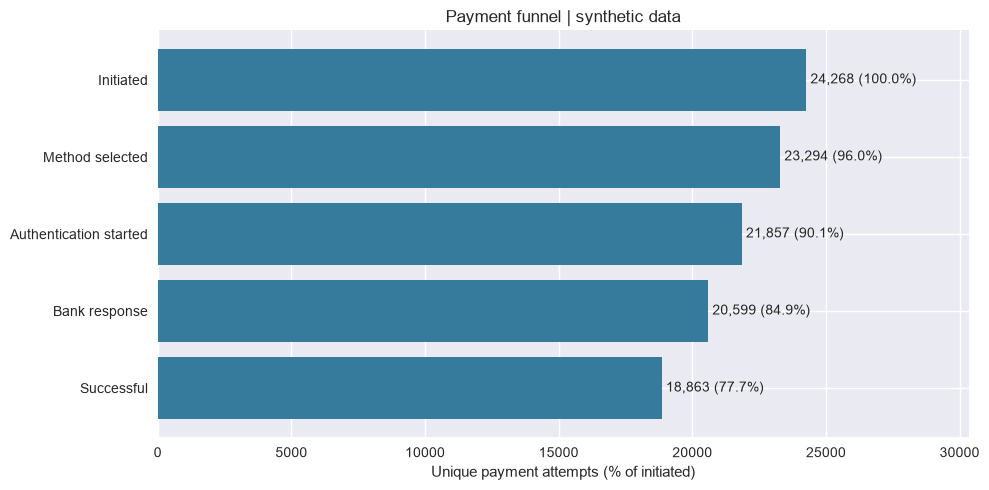

In [28]:
fig, ax = plt.subplots(figsize=(10, 5))
labels = ['Initiated', 'Method selected', 'Authentication started', 'Bank response', 'Successful']
ax.barh(labels, funnel.attempts, color='#367b9c')
for i, row in enumerate(funnel.itertuples()):
    ax.text(row.attempts + 150, i, f'{row.attempts:,} ({row.overall_pct:.1f}%)', va='center')
ax.invert_yaxis()
ax.set_xlim(0, len(payment_data) * 1.25)
ax.set_xlabel('Unique payment attempts (% of initiated)')
ax.set_title('Payment funnel | synthetic data')
fig.tight_layout()
fig.savefig(OUTPUT / 'payment_funnel.png', dpi=160)
plt.show()

### Funnel Insights
**Observation:** The largest drop is between bank response and payment success: 1,736 attempts, or 8.43% of the previous stage. Overall payment completion is 77.73%.

**Hypothesis:** A bank response can communicate a decline or technical error. This drop is not automatically abandonment. I need to separate the confirmed failure reasons before recommending a change. The largest drop does not necessarily have the highest product priority.

### Payment Failure Analysis

In [29]:
failed_payments = payment_data[payment_data['payment_status'] == 'failed'].copy()
failure_summary = failed_payments['failure_reason'].value_counts().to_frame('failures')

failure_summary['share_of_failures_pct'] = failure_summary['failures'] / len(failed_payments) * 100
failure_summary['rate_of_resolved_pct'] = failure_summary['failures'] / len(resolved_payments) * 100
failure_summary.round(2)

,failures,share_of_failures_pct,rate_of_resolved_pct
failure_reason,,,
authentication_failure,1253,41.92,5.73
confirmed_technical_error,1061,35.50,4.86
bank_decline,675,22.58,3.09


### Failure Rates by Bank, Device, Time and Amount
I compare rates with sample sizes because the bank with the most failures may simply process more attempts.

In [30]:
payment_data['is_success'] = payment_data['payment_status'] == 'success'
payment_data['is_failed'] = payment_data['payment_status'] == 'failed'
payment_data['is_resolved'] = payment_data['payment_status'].isin(['success', 'failed'])

payment_data['time_of_day'] = pd.cut(payment_data['attempt_timestamp'].dt.hour, [-1, 5, 11, 17, 23],
                                     labels=['Night', 'Morning', 'Afternoon', 'Evening'])
payment_data['amount_range'] = pd.cut(payment_data['payment_amount'], [0, 500, 3000, np.inf],
                                     labels=['<=500', '501-3000', '>3000'])

In [31]:
def segment_summary(df, column):
    summary_df = df.groupby(column, observed=True).agg({
        'attempt_id': 'count',
        'user_id': 'nunique',
        'is_success': 'sum',
        'is_failed': 'sum',
        'is_resolved': 'sum',
        'is_retry': 'sum'
    })
    summary_df.columns = ['attempts', 'users', 'successes', 'failures', 'resolved', 'retries']

    summary_df['success_pct'] = summary_df['successes'] / summary_df['attempts'] * 100
    summary_df['failure_pct_resolved'] = summary_df['failures'] / summary_df['resolved'].replace(0, np.nan) * 100
    summary_df['retry_share_pct'] = summary_df['retries'] / summary_df['attempts'] * 100

    retry_payments = df[df['is_retry']]
    summary_df['retry_success_pct'] = retry_payments.groupby(column, observed=True)['is_success'].mean() * 100

    return summary_df

In [32]:
bank_summary = segment_summary(payment_data, 'bank_name')
bank_summary.round(2)

,attempts,users,successes,failures,resolved,retries,success_pct,failure_pct_resolved,retry_share_pct,retry_success_pct
bank_name,,,,,,,,,,
Bank A,9392,3287,7474,975,8449,370,79.58,11.54,3.94,78.92
Bank B,7191,2625,5565,898,6463,344,77.39,13.89,4.78,76.74
Bank C,4940,1921,3796,663,4459,259,76.84,14.87,5.24,77.99
Bank D,2745,1236,2028,453,2481,175,73.88,18.26,6.38,72.00


In [33]:
device_summary = segment_summary(payment_data, 'device_type')
device_summary.round(2)

,attempts,users,successes,failures,resolved,retries,success_pct,failure_pct_resolved,retry_share_pct,retry_success_pct
device_type,,,,,,,,,,
Android,19879,6212,15374,2517,17891,961,77.34,14.07,4.83,77.00
iOS,4389,1343,3489,472,3961,187,79.49,11.92,4.26,77.01


In [34]:
time_summary = segment_summary(payment_data, 'time_of_day')
time_summary.round(2)

,attempts,users,successes,failures,resolved,retries,success_pct,failure_pct_resolved,retry_share_pct,retry_success_pct
time_of_day,,,,,,,,,,
Night,984,863,744,134,878,56,75.61,15.26,5.69,80.36
Morning,7828,4518,6072,971,7043,355,77.57,13.79,4.54,78.03
Afternoon,4245,3008,3312,507,3819,215,78.02,13.28,5.06,76.28
Evening,11211,5544,8735,1377,10112,522,77.91,13.62,4.66,76.25


In [35]:
amount_summary = segment_summary(payment_data, 'amount_range')
amount_summary.round(2)

,attempts,users,successes,failures,resolved,retries,success_pct,failure_pct_resolved,retry_share_pct,retry_success_pct
amount_range,,,,,,,,,,
<=500,13062,5465,10144,1602,11746,618,77.66,13.64,4.73,77.83
501-3000,10058,4727,7845,1223,9068,463,78.00,13.49,4.60,76.24
>3000,1148,786,874,164,1038,67,76.13,15.80,5.84,74.63


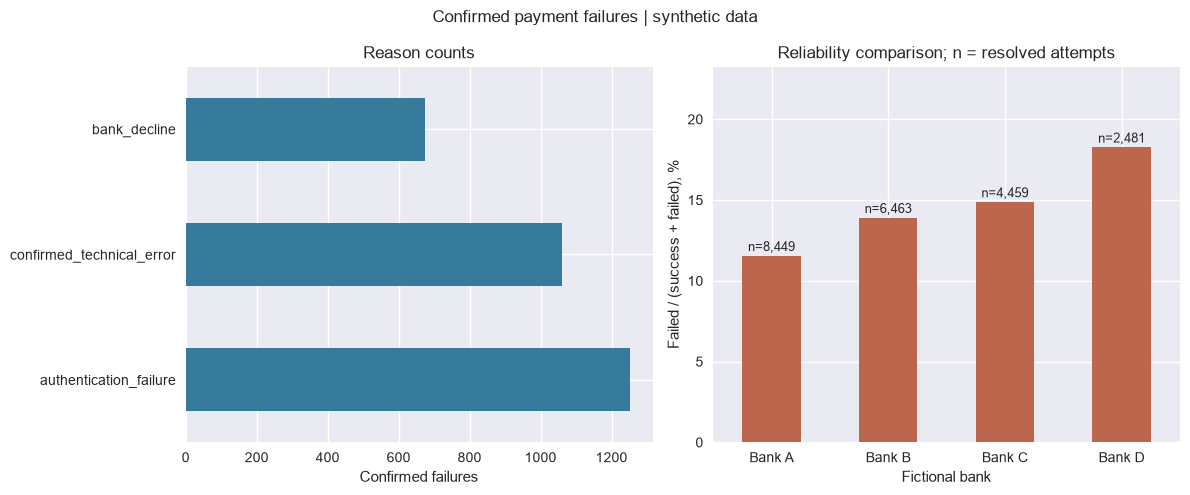

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
failure_summary.failures.plot.barh(ax=axes[0], color='#367b9c')
axes[0].set_xlabel('Confirmed failures')
axes[0].set_ylabel('')
axes[0].set_title('Reason counts')
bank_summary.failure_pct_resolved.plot.bar(ax=axes[1], color='#bd664e', rot=0)
for i, row in enumerate(bank_summary.itertuples()):
    axes[1].text(i, row.failure_pct_resolved + 0.3, f'n={row.resolved:,}', ha='center', fontsize=9)
axes[1].set_ylim(0, bank_summary.failure_pct_resolved.max() + 5)
axes[1].set_ylabel('Failed / (success + failed), %')
axes[1].set_xlabel('Fictional bank')
axes[1].set_title('Reliability comparison; n = resolved attempts')
fig.suptitle('Confirmed payment failures | synthetic data')
fig.tight_layout()
fig.savefig(OUTPUT / 'failure_analysis.png', dpi=160)
plt.show()

### Failure Insights
**Observation:** Authentication failure is the largest confirmed-failure category, with 1,253 attempts. Bank D has the highest overall failure rate among resolved outcomes: 18.26%, compared with 11.54% for Bank A.

**Hypothesis:** Authentication guidance or provider availability could explain similar patterns in a real product. Here, these patterns reflect the simulation assumptions. Error codes, incident logs and user research would be needed to confirm an operational cause.

### SQL Product Analytics
I loaded the tables into an in-memory SQLite database and used the queries in `analysis_queries.sql`.

In [37]:
connection = sqlite3.connect(':memory:')
user_data.to_sql('users', connection, index=False, if_exists='replace')
payment_data.to_sql('payment_attempts', connection, index=False, if_exists='replace')
event_data.to_sql('payment_events', connection, index=False, if_exists='replace')

108881

In [38]:
with open('analysis_queries.sql') as file:
    sql_text = file.read()

sql_queries = []
for query in sql_text.split(';'):
    if query.strip():
        sql_queries.append(query)

#### Daily Payment Success

In [39]:
sql_result_1 = pd.read_sql_query(sql_queries[0], connection)
sql_result_1.head(10)

,day,attempts,success_pct,pending_pct,abandoned_pct
0,2026-01-01,13,92.307692,0.0,7.692308
1,2026-01-02,17,76.470588,0.0,5.882353
2,2026-01-03,25,80.000000,0.0,8.000000
3,2026-01-04,47,74.468085,0.0,14.893617
4,2026-01-05,54,81.481481,0.0,11.111111
5,2026-01-06,42,76.190476,0.0,11.904762
6,2026-01-07,72,84.722222,0.0,8.333333
7,2026-01-08,47,70.212766,0.0,10.638298
8,2026-01-09,54,79.629630,0.0,12.962963
9,2026-01-10,72,80.555556,0.0,6.944444


#### Bank-wise Failure Rate

In [40]:
sql_result_2 = pd.read_sql_query(sql_queries[1], connection)
sql_result_2.head(10)

,bank_name,attempts,resolved,failure_pct
0,Bank D,2745,2481,18.258767
1,Bank C,4940,4459,14.868805
2,Bank B,7191,6463,13.894476
3,Bank A,9392,8449,11.539827


#### Device-wise Payment Conversion

In [41]:
sql_result_3 = pd.read_sql_query(sql_queries[2], connection)
sql_result_3.head(10)

,device_type,attempts,users,success_pct
0,Android,19879,6212,77.337894
1,iOS,4389,1343,79.494190


#### Confirmed Failure Reasons

In [42]:
sql_result_4 = pd.read_sql_query(sql_queries[3], connection)
sql_result_4.head(10)

,failure_reason,failures,share_of_failures_pct
0,authentication_failure,1253,41.920375
1,confirmed_technical_error,1061,35.496822
2,bank_decline,675,22.582804


#### First Successful Payment

In [43]:
sql_result_5 = pd.read_sql_query(sql_queries[4], connection)
sql_result_5.head(10)

,user_id,first_success
0,U00001,2026-01-19 18:30:00
1,U00002,2026-01-28 14:07:00
2,U00003,2026-05-01 11:41:00
3,U00004,2026-01-26 08:14:00
4,U00005,2026-01-19 14:08:00
5,U00006,2026-06-13 18:05:00
6,U00007,2026-01-28 14:28:00
7,U00008,2026-03-16 21:04:00
8,U00009,2026-03-30 18:58:00
9,U00010,2026-01-25 08:11:00


#### Weekly Successful Activity

In [44]:
sql_result_6 = pd.read_sql_query(sql_queries[5], connection)
sql_result_6.head(10)

,week_start,successful_users,users_with_multiple_successes
0,2025-12-29,76,4
1,2026-01-05,287,31
2,2026-01-12,345,43
3,2026-01-19,377,39
4,2026-01-26,464,75
5,2026-02-02,463,61
6,2026-02-09,570,80
7,2026-02-16,600,67
8,2026-02-23,615,71
9,2026-03-02,616,67


#### Retry Attempts After Failure

In [45]:
sql_result_7 = pd.read_sql_query(sql_queries[6], connection)
sql_result_7.head(10)

,attempt_id,user_id,payment_status
0,A000016,U00004,success
1,A000028,U00008,success
2,A000035,U00010,success
3,A000067,U00020,success
4,A000091,U00029,success
5,A000126,U00045,success
6,A000128,U00045,success
7,A000133,U00046,abandoned
8,A000146,U00051,success
9,A000190,U00065,success


#### Ranking Banks by Failure Rate

In [46]:
sql_result_8 = pd.read_sql_query(sql_queries[7], connection)
sql_result_8.head(10)

,bank_name,resolved,failure_pct,failure_rank
0,Bank D,2481,18.258767,1
1,Bank C,4459,14.868805,2
2,Bank B,6463,13.894476,3
3,Bank A,8449,11.539827,4


#### Comparing SQL and Pandas Results
I joined the bank-rate results to check that both calculations use the same denominator. A zero difference means they agree.

In [47]:
bank_comparison = bank_summary[['failure_pct_resolved']].merge(sql_result_2[['bank_name', 'failure_pct']],
                                                            left_index=True, right_on='bank_name')
bank_comparison['difference'] = bank_comparison['failure_pct_resolved'] - bank_comparison['failure_pct']
bank_comparison.round(6)

,failure_pct_resolved,bank_name,failure_pct,difference
3,11.539827,Bank A,11.539827,0.0
2,13.894476,Bank B,13.894476,0.0
1,14.868805,Bank C,14.868805,0.0
0,18.258767,Bank D,18.258767,0.0


In [48]:
print('Retry attempts from Pandas:', len(retry_data))
print('Retry attempts from SQL:', len(sql_result_7))

retry_comparison = retry_data[['attempt_id']].merge(sql_result_7[['attempt_id']], on='attempt_id', how='outer', indicator=True)
retry_comparison['_merge'].value_counts()

Retry attempts from Pandas: 1148
Retry attempts from SQL: 1148


_merge
both          1148
left_only        0
right_only       0
Name: count, dtype: int64

### User Segmentation
New means a user’s first-ever attempt. All later attempts are returning, including an immediate retry. These are attempt-level groups, not separate sets of people.

In [49]:
payment_data['user_segment'] = 'Returning'
first_attempt_index = payment_data.groupby('user_id').head(1).index
payment_data.loc[first_attempt_index, 'user_segment'] = 'New'

payment_data = payment_data.merge(user_data[['user_id', 'city_tier', 'acquisition_channel']], on='user_id')

In [50]:
new_returning_summary = segment_summary(payment_data, 'user_segment')
new_returning_summary.round(2)

,attempts,users,successes,failures,resolved,retries,success_pct,failure_pct_resolved,retry_share_pct,retry_success_pct
user_segment,,,,,,,,,,
New,7555,7555,5727,894,6621,0,75.8,13.50,0.00,NaN
Returning,16713,5356,13136,2095,15231,1148,78.6,13.75,6.87,77.0


In [51]:
city_summary = segment_summary(payment_data, 'city_tier')
city_summary.round(2)

,attempts,users,successes,failures,resolved,retries,success_pct,failure_pct_resolved,retry_share_pct,retry_success_pct
city_tier,,,,,,,,,,
Tier 1,9363,2959,7277,1168,8445,441,77.72,13.83,4.71,76.64
Tier 2,8407,2651,6550,1048,7598,396,77.91,13.79,4.71,76.01
Tier 3,6498,1945,5036,773,5809,311,77.50,13.31,4.79,78.78


In [52]:
user_segments = {
    'user_segment': new_returning_summary,
    'device_type': device_summary
}

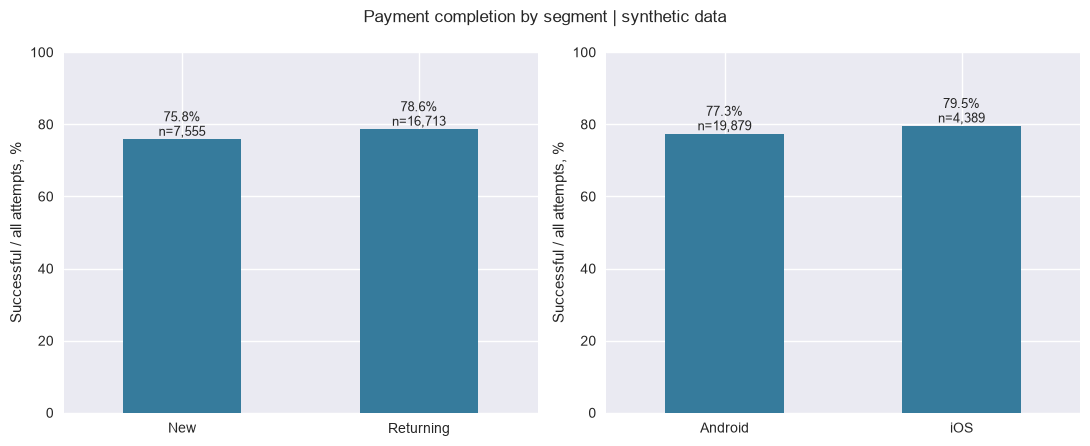

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, column in zip(axes, ['user_segment', 'device_type']):
    table = user_segments[column]
    table.success_pct.plot.bar(ax=ax, rot=0, color='#367b9c')
    for i, row in enumerate(table.itertuples()):
        ax.text(i, row.success_pct + 1, f'{row.success_pct:.1f}%\nn={row.attempts:,}', ha='center', fontsize=9)
    ax.set_ylim(0, 100)
    ax.set_ylabel('Successful / all attempts, %')
    ax.set_xlabel('')
fig.suptitle('Payment completion by segment | synthetic data')
fig.tight_layout()
fig.savefig(OUTPUT / 'segment_comparison.png', dpi=160)
plt.show()

### Segment Insights
**Observation:** Later attempts have a 78.6% success rate, compared with 75.8% on first attempts. Android success is 77.3%, compared with 79.5% on iOS.

**Hypothesis:** First-time users may need more guidance, while the device gap could relate to authentication behaviour. The generator includes both types of variation. These comparisons alone do not prove an onboarding or device defect. Small groups and repeated attempts from the same users need caution.

### Weekly Cohort Retention
A user's first successful payment determines their cohort week. Weeks run Monday to Sunday. Week 1 means the next calendar week, not days 7–13 after each user's first payment.

Retention is the percentage of cohort users with at least one successful payment in that later week. Week 0 is 100% by definition. I leave a cell blank if its full week has not been observed by the July 1 cutoff.

In [54]:
successful_payments = payment_data[payment_data['payment_status'] == 'success'].copy()
first_success = successful_payments.groupby('user_id')['attempt_timestamp'].min().reset_index()
first_success.columns = ['user_id', 'first_success']
first_success['cohort_week'] = first_success['first_success'].dt.to_period('W-SUN').dt.start_time
first_success.head()

,user_id,first_success,cohort_week
0,U00001,2026-01-19 18:30:00,2026-01-19
1,U00002,2026-01-28 14:07:00,2026-01-26
2,U00003,2026-05-01 11:41:00,2026-04-27
3,U00004,2026-01-26 08:14:00,2026-01-26
4,U00005,2026-01-19 14:08:00,2026-01-19


In [55]:
retention_data = successful_payments.merge(first_success[['user_id', 'cohort_week']], on='user_id')
retention_data['activity_week'] = retention_data['attempt_timestamp'].dt.to_period('W-SUN').dt.start_time
retention_data['week_number'] = (retention_data['activity_week'] - retention_data['cohort_week']).dt.days // 7
retention_data[['user_id', 'cohort_week', 'activity_week', 'week_number']].head()

,user_id,cohort_week,activity_week,week_number
0,U00001,2026-01-19,2026-01-19,0
1,U00002,2026-01-26,2026-01-26,0
2,U00002,2026-01-26,2026-02-02,1
3,U00002,2026-01-26,2026-03-02,5
4,U00003,2026-04-27,2026-04-27,0


In [56]:
cohort_sizes = first_success.groupby('cohort_week')['user_id'].nunique()
cohort_counts = pd.pivot_table(retention_data, index='cohort_week', columns='week_number',
                               values='user_id', aggfunc='nunique')
cohort_counts = cohort_counts.reindex(index=cohort_sizes.index, columns=range(9)).fillna(0)
cohort_table = cohort_counts.divide(cohort_sizes, axis=0) * 100

In [57]:
eligible_sizes = pd.DataFrame(index=cohort_sizes.index, columns=range(9), dtype=float)

# A recent cohort is not counted as lost when its follow-up week is still incomplete.
for cohort_week in cohort_table.index:
    for week in cohort_table.columns:
        week_end = cohort_week + pd.Timedelta(weeks=week + 1)
        if week_end > OBSERVATION_END:
            cohort_table.loc[cohort_week, week] = np.nan
        else:
            eligible_sizes.loc[cohort_week, week] = cohort_sizes.loc[cohort_week]

cohort_table.round(1)

week_number,0,1,2,3,4,5,6,7,8
cohort_week,,,,,,,,,
2025-12-29,100.0,36.8,18.4,17.1,14.5,19.7,15.8,7.9,6.6
2026-01-05,100.0,21.6,22.4,23.2,15.8,16.6,15.1,12.4,10.0
2026-01-12,100.0,20.4,22.9,20.0,17.1,13.1,14.5,9.1,9.8
2026-01-19,100.0,25.2,22.0,19.6,21.6,15.6,16.4,10.8,11.2
2026-01-26,100.0,17.6,19.1,18.0,14.6,11.2,15.7,10.5,10.9
2026-02-02,100.0,25.6,22.8,18.4,13.6,16.4,13.6,8.0,10.8
2026-02-09,100.0,22.4,19.1,21.7,16.4,13.8,15.1,9.2,10.9
2026-02-16,100.0,23.6,21.2,20.5,15.1,17.1,11.6,14.4,7.2
2026-02-23,100.0,21.3,25.4,16.7,19.2,17.1,14.3,9.8,10.1


In [58]:
# Weight by eligible users, rather than giving small and large cohorts equal weight.
weighted_retention = (cohort_table * eligible_sizes).sum() / eligible_sizes.sum()
retention_summary = pd.DataFrame({'eligible_users': eligible_sizes.sum(), 'retention_pct': weighted_retention})
retention_summary.round(2)

,eligible_users,retention_pct
0,6742.0,100.00
1,6691.0,23.15
2,6415.0,21.36
3,6170.0,18.51
4,5919.0,15.91
5,5619.0,14.84
6,5363.0,13.46
7,5082.0,10.92
8,4795.0,9.89


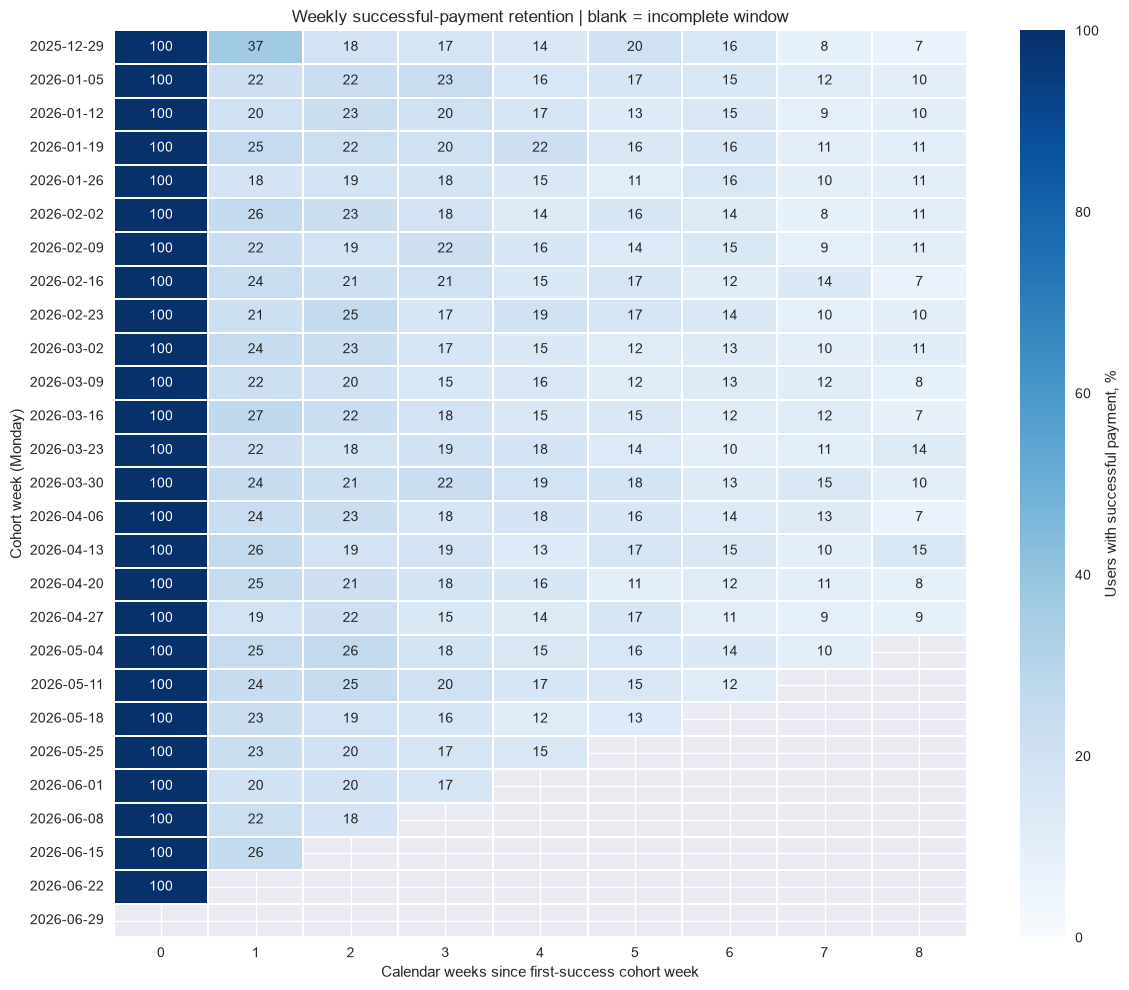

In [59]:
fig, ax = plt.subplots(figsize=(12, 10))
heatmap = cohort_table.copy()
heatmap.index = heatmap.index.strftime('%Y-%m-%d')
sns.heatmap(heatmap, annot=True, fmt='.0f', cmap='Blues', vmin=0, vmax=100, linewidths=0.3,
            cbar_kws={'label': 'Users with successful payment, %'}, ax=ax)
ax.set_xlabel('Calendar weeks since first-success cohort week')
ax.set_ylabel('Cohort week (Monday)')
ax.set_title('Weekly successful-payment retention | blank = incomplete window')
fig.tight_layout()
fig.savefig(OUTPUT / 'retention_heatmap.png', dpi=160)
plt.show()

### Retention Insights
**Observation:** Eligible-user-weighted retention is 23.15% in Week 1, 15.91% in Week 4 and 9.89% in Week 8.

**Hypothesis:** Payment usage can be irregular, and some users stop transacting in the simulation. A user who skips one week may return later, so weekly inactivity does not prove permanent churn.

### First-Payment Experience
Do users whose first attempt fails behave differently from users whose first attempt succeeds?

I compare users with at least 30 days of observation. The outcome is any later successful payment within 30 days of the first attempt. The original first success is excluded, but recovery after a first failure is included. Users whose first attempt was pending or abandoned are excluded from this comparison.

In [60]:
first_attempts = payment_data.groupby('user_id').head(1)[['user_id', 'attempt_timestamp', 'payment_status']].copy()
first_attempts.columns = ['user_id', 'first_attempt_time', 'first_status']

eligible_first = first_attempts[first_attempts['first_status'].isin(['success', 'failed'])].copy()
eligible_first = eligible_first[eligible_first['first_attempt_time'] + pd.Timedelta(days=30) < OBSERVATION_END]
eligible_first.head()

,user_id,first_attempt_time,first_status
0,U00001,2026-01-19 18:30:00,success
2,U00002,2026-01-28 14:07:00,success
6,U00003,2026-05-01 11:41:00,success
14,U00004,2026-01-26 08:07:00,failed
20,U00005,2026-01-19 14:08:00,success


In [61]:
future_success = successful_payments[['user_id', 'attempt_timestamp']].merge(eligible_first, on='user_id')
future_success = future_success[
    (future_success['attempt_timestamp'] > future_success['first_attempt_time']) &
    (future_success['attempt_timestamp'] <= future_success['first_attempt_time'] + pd.Timedelta(days=30))
]

participating_users = future_success['user_id'].unique()
eligible_first['participated'] = eligible_first['user_id'].isin(participating_users)

In [62]:
first_experience = eligible_first.groupby('first_status').agg({'user_id': 'count', 'participated': 'sum'})
first_experience.columns = ['users', 'returning_users']
first_experience['participation_pct'] = first_experience['returning_users'] / first_experience['users'] * 100
first_experience.round(2)

,users,returning_users,participation_pct
first_status,,,
failed,769,443,57.61
success,5061,2975,58.78


In [63]:
participation_gap = first_experience.loc['success', 'participation_pct'] - first_experience.loc['failed', 'participation_pct']
print(f'Difference: {participation_gap:.2f} percentage points')

Difference: 1.18 percentage points


### First-Payment Insights
**Observation:** Among eligible users, 58.78% of the successful-first group and 57.61% of the failed-first group made a later successful payment within 30 days. The groups contain 5,061 and 769 users respectively. The difference is 1.18 percentage points.

**Limitation:** This is an observational comparison. User intent, amount, bank and device may differ. The simulation also changes later usage probabilities after different outcomes. I cannot conclude that the first failure caused lower retention.

### Investigating the Main Product Problem
I selected the largest individual confirmed-failure reason after comparing the counts. This is a starting point; effort and customer harm would also matter when prioritizing a real change.

In [64]:
selected_reason = failure_summary['failures'].idxmax()
print('Selected failure reason:', selected_reason)
print('Affected attempts:', failure_summary.loc[selected_reason, 'failures'])

Selected failure reason: authentication_failure
Affected attempts: 1253


In [65]:
reason_by_bank = payment_data.groupby('bank_name')['is_resolved'].sum().to_frame('resolved')
selected_failures = payment_data[payment_data['failure_reason'] == selected_reason]
reason_by_bank['selected_failures'] = selected_failures.groupby('bank_name')['attempt_id'].count()
reason_by_bank['selected_reason_pct_resolved'] = reason_by_bank['selected_failures'] / reason_by_bank['resolved'] * 100
reason_by_bank.round(2)

,resolved,selected_failures,selected_reason_pct_resolved
bank_name,,,
Bank A,8449,477,5.65
Bank B,6463,395,6.11
Bank C,4459,259,5.81
Bank D,2481,122,4.92


In [66]:
reason_by_device = payment_data.groupby('device_type')['is_resolved'].sum().to_frame('resolved')
reason_by_device['selected_failures'] = selected_failures.groupby('device_type')['attempt_id'].count()
reason_by_device['selected_reason_pct_resolved'] = reason_by_device['selected_failures'] / reason_by_device['resolved'] * 100
reason_by_device.round(2)

,resolved,selected_failures,selected_reason_pct_resolved
device_type,,,
Android,17891,1108,6.19
iOS,3961,145,3.66


In [67]:
pd.crosstab(selected_failures['time_of_day'], selected_failures['user_segment'])

user_segment,New,Returning
time_of_day,,
Night,18,29
Morning,112,312
Afternoon,55,150
Evening,184,393


### Product Investigation
**Observed Problem:** Authentication failure is the largest individual failure category, affecting 1,253 attempts.

**Supporting Evidence:** Authentication failures represent 6.19% of resolved Android outcomes and 3.66% of resolved iOS outcomes. The tables above show their distribution by bank, time and first versus later attempts.

**Possible Explanations:** Users may not understand the error or the next step. Authentication flows might differ by device. These are hypotheses; the dataset does not contain screen behaviour or user feedback. The device difference is also part of the simulation assumptions.

**Missing Information:** Actual error codes, device and app logs, screen recordings, payment-status history, support contacts and user interviews.

**Recommended Next Step:** Validate the error messages and study how users recover from confirmed authentication failures.

### Product Recommendation
**Clearer authentication-failure messages and recovery guidance.**

Target users whose payment has a confirmed authentication failure. Explain the documented reason and show an appropriate next step, such as checking credentials before another attempt. Check payment status before offering a retry. Pending users should receive status checking and support.

This may help users understand what happened and complete a payment. It cannot fix provider outages. Poor guidance could also encourage repeated attempts, add friction or create duplicate-payment risk if the status is stale.

The main success metric would be the percentage of affected users making a successful payment within 24 hours. A higher retry count by itself is not success.

### A/B Testing Proposal
- **Hypothesis:** Clearer guidance after the selected confirmed failure increases the fraction of affected users making a successful payment within 24 hours.
- **Eligibility:** First occurrence per user of the confirmed authentication-failure reason during enrollment. Confirm final failed status before exposure. Exclude pending outcomes. Define eligibility before assigning treatment.
- **Control:** Current generic confirmed-failure message and existing actions.
- **Treatment:** Reason-specific explanation plus safe recovery options, including status check before a retry and an alternative linked bank where relevant.
- **Randomization:** 50/50 at user level, persistent assignment. Analyze all randomized eligible users in their assigned arm, including those who ignore the message. This avoids exposing one person to both experiences across sessions.
- **Primary metric:** Eligible randomized users with any successful payment in (trigger time, trigger time + 24 hours] / all eligible randomized users. Track same-intent recovery separately once intent IDs exist.
- **Secondary metric:** At least one later successful payment within 30 days; mature all windows before analysis.
- **Guardrails:** Duplicate debits per eligible user, pending incidents per eligible user, support contacts per eligible user, and p95 end-to-end payment latency. Do not optimize retry count.
- **Planning:** Estimate the real baseline first. As an illustrative plan, detect a 3 percentage-point absolute primary-metric lift at 80% power with a two-sided 5% significance level. This is a chosen minimum detectable effect, not a forecast. Calculate sample size from the measured baseline; simulate nothing as experiment evidence. Run for at least two full weeks and until the preplanned sample is enrolled, then wait 24 hours for the last primary window. Wait 30 days for the secondary readout.
- **Success:** Pre-register the analysis. Require a positive primary difference whose 95% confidence interval excludes zero and an estimate of at least 3 percentage points. Example guardrail margins to agree before launch: duplicate-debit increase <=0.1 points, pending increase <=0.5 points, support-contact increase <=1 point, p95 latency increase <=10%. Require upper confidence bounds below harm margins for rate guardrails; otherwise collect more evidence or do not ship. Investigate every confirmed duplicate debit. Use a fixed analysis date and no repeated significance peeking.

No live experiment, launch, or measured uplift is claimed.

### Final Results

In [68]:
final_results = {
    'Payment success rate (% of attempts)': success_rate,
    'Confirmed failure rate (% of resolved)': failure_rate,
    'Pending share (% of attempts)': status_summary.loc['pending', 'share_pct'],
    'Abandonment share (% of attempts)': status_summary.loc['abandoned', 'share_pct'],
    'Retry success rate (% of eligible retries)': retry_success_rate,
    'Week 1 retention (%)': weighted_retention.loc[1],
    'Week 4 retention (%)': weighted_retention.loc[4],
    '30-day participation difference (points)': participation_gap
}

pd.DataFrame(final_results.items(), columns=['Metric', 'Value']).round(2)

,Metric,Value
0,Payment success rate (% of attempts),77.73
1,Confirmed failure rate (% of resolved),13.68
2,Pending share (% of attempts),0.02
3,Abandonment share (% of attempts),9.93
4,Retry success rate (% of eligible retries),77.00
5,Week 1 retention (%),23.15
6,Week 4 retention (%),15.91
7,30-day participation difference (points),1.18


In [69]:
print('Initiated attempts:', len(payment_data))
print('Attempts across final statuses:', status_summary['attempts'].sum())
print('Successful attempts:', len(successful_payments))
print('Final funnel-stage attempts:', funnel.loc['payment_successful', 'attempts'])

connection.close()

Initiated attempts: 24268
Attempts across final statuses: 24268
Successful attempts: 18863
Final funnel-stage attempts: 18863


### Final Recommendations and Limitations
- Investigate authentication failures first, especially the Android experience. Keep fictional Bank D's higher overall failure rate as a separate reliability investigation.
- Test clearer authentication-failure guidance using user-level randomization and 24-hour successful-payment participation. Monitor duplicate debits, pending incidents, support demand and latency.
- Do not overstate the 1.18-point participation gap after first-payment outcomes. It is an association, not evidence of causality.
- The data is synthetic, transaction behaviour is simulated, retries are identified using a proxy, and pending outcomes use a simplified snapshot. There is no real provider validation, deployed feature or measured experimental uplift.